# 01 — Análise Exploratória de Dados (EDA) e Divisão Estratificada

**Atividade Final de Redes Neurais Artificiais — EAD Unifor (TrashNet)**

Este notebook inspeciona o dataset oficial `dataset-resized.zip` (2.527 imagens em `512 × 384`), verifica integridade, dimensões, canais de cor e duplicações, realiza a divisão estratificada fixa (70% treino, 15% validação, 15% teste com `seed = 42`) e exibe a distribuição e exemplos das 6 classes.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

BASE_DIR = Path('..').resolve()
with open(BASE_DIR / 'results' / 'eda_summary.json', 'r', encoding='utf-8') as f:
    eda = json.load(f)

print('Total de imagens:', eda['total_images'])
print('Arquivos corrompidos:', eda['corrupted_files'])
print('Dimensões:', eda['dimensions_summary'])
print('Modos de cor:', eda['color_modes'])
print('Pares MD5 idênticos encontrados:', eda['duplicate_md5_pairs'])
print('Totais por divisão (seed=42):', eda['split_totals'])
print('Média RGB no treino [0,1]:', eda['train_rgb_mean_0_1'])
print('Desvio padrão RGB no treino [0,1]:', eda['train_rgb_std_0_1'])

Total de imagens: 2527
Arquivos corrompidos: 0
Dimensões: [{'width': 512, 'height': 384, 'count': 2527}]
Modos de cor: {'RGB': 2527}
Pares MD5 idênticos encontrados: [['plastic/plastic152.jpg', 'glass/glass176.jpg'], ['plastic/plastic332.jpg', 'glass/glass389.jpg'], ['metal/metal91.jpg', 'glass/glass115.jpg']]
Totais por divisão (seed=42): {'train': 1768, 'val': 379, 'test': 380}
Média RGB no treino [0,1]: [0.6727, 0.6396, 0.6045]
Desvio padrão RGB no treino [0,1]: [0.1836, 0.1826, 0.1933]


In [2]:
df_dist = pd.DataFrame(eda['class_distribution']).T
display(df_dist)

,total,train,val,test,pct_total,class_weight
glass,501.0,350.0,75.0,76.0,19.83,0.8419
paper,594.0,416.0,89.0,89.0,23.51,0.7083
cardboard,403.0,282.0,61.0,60.0,15.95,1.0449
plastic,482.0,337.0,72.0,73.0,19.07,0.8744
metal,410.0,287.0,61.0,62.0,16.22,1.0267
trash,137.0,96.0,21.0,20.0,5.42,3.0694


## Distribuição Estratificada e Exemplos Visuais

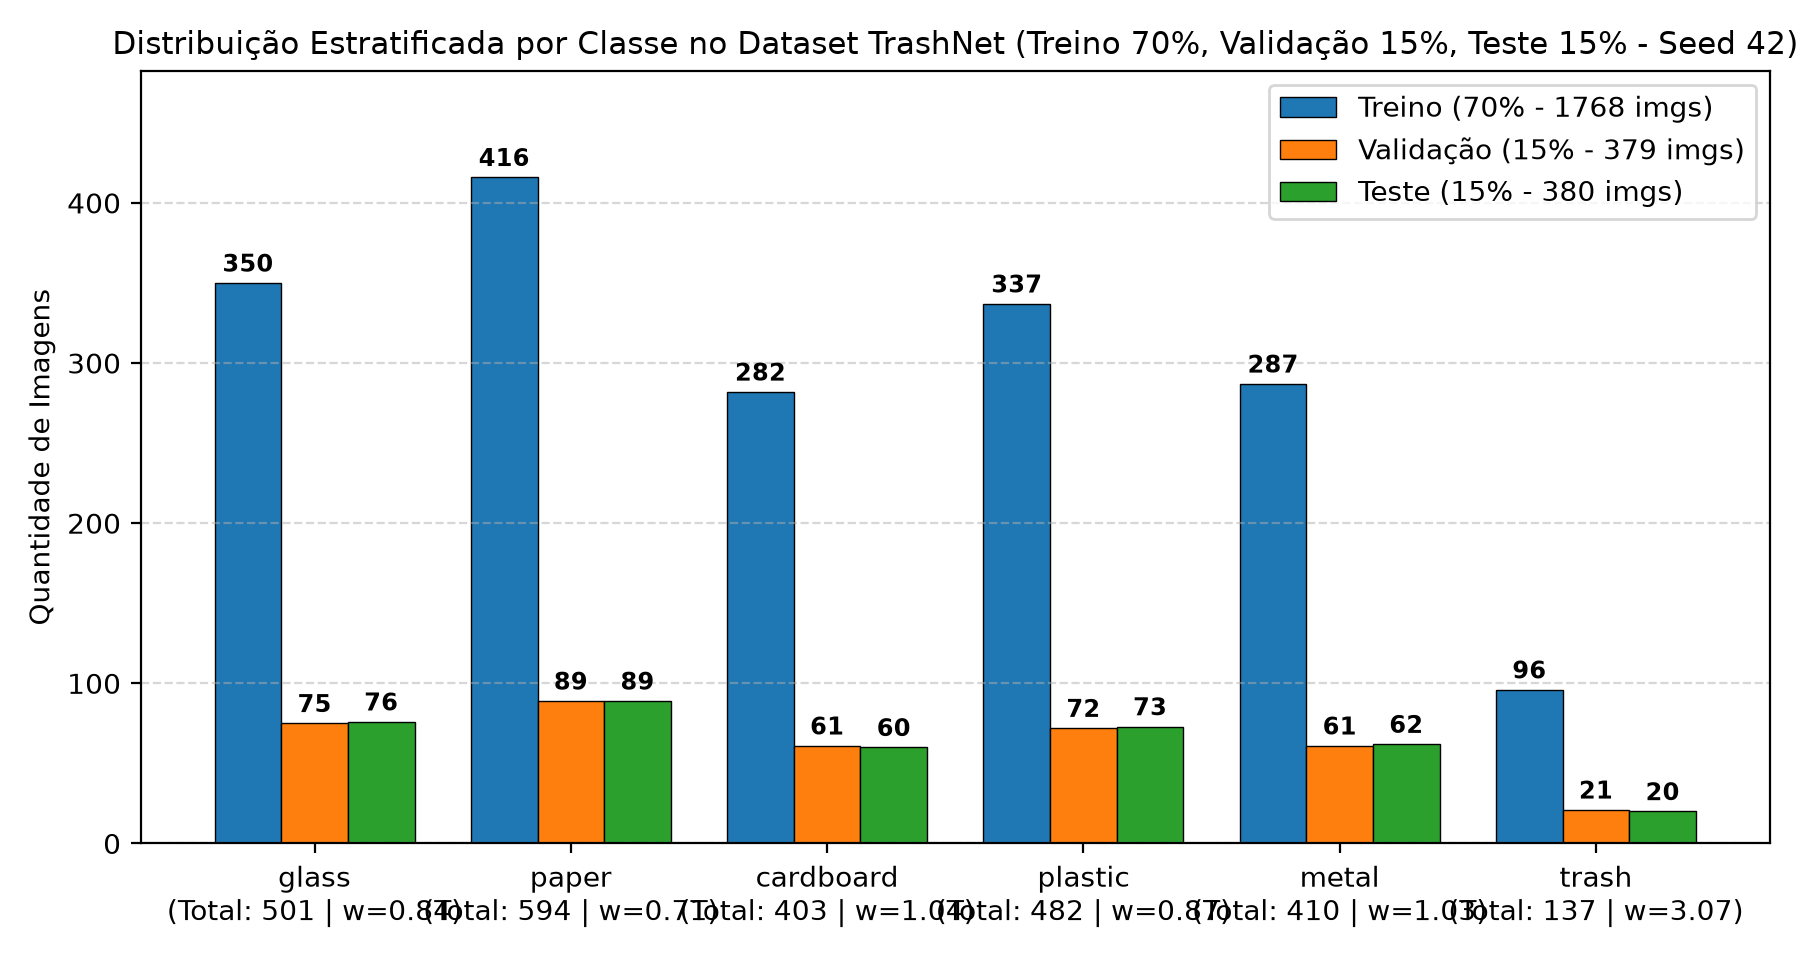

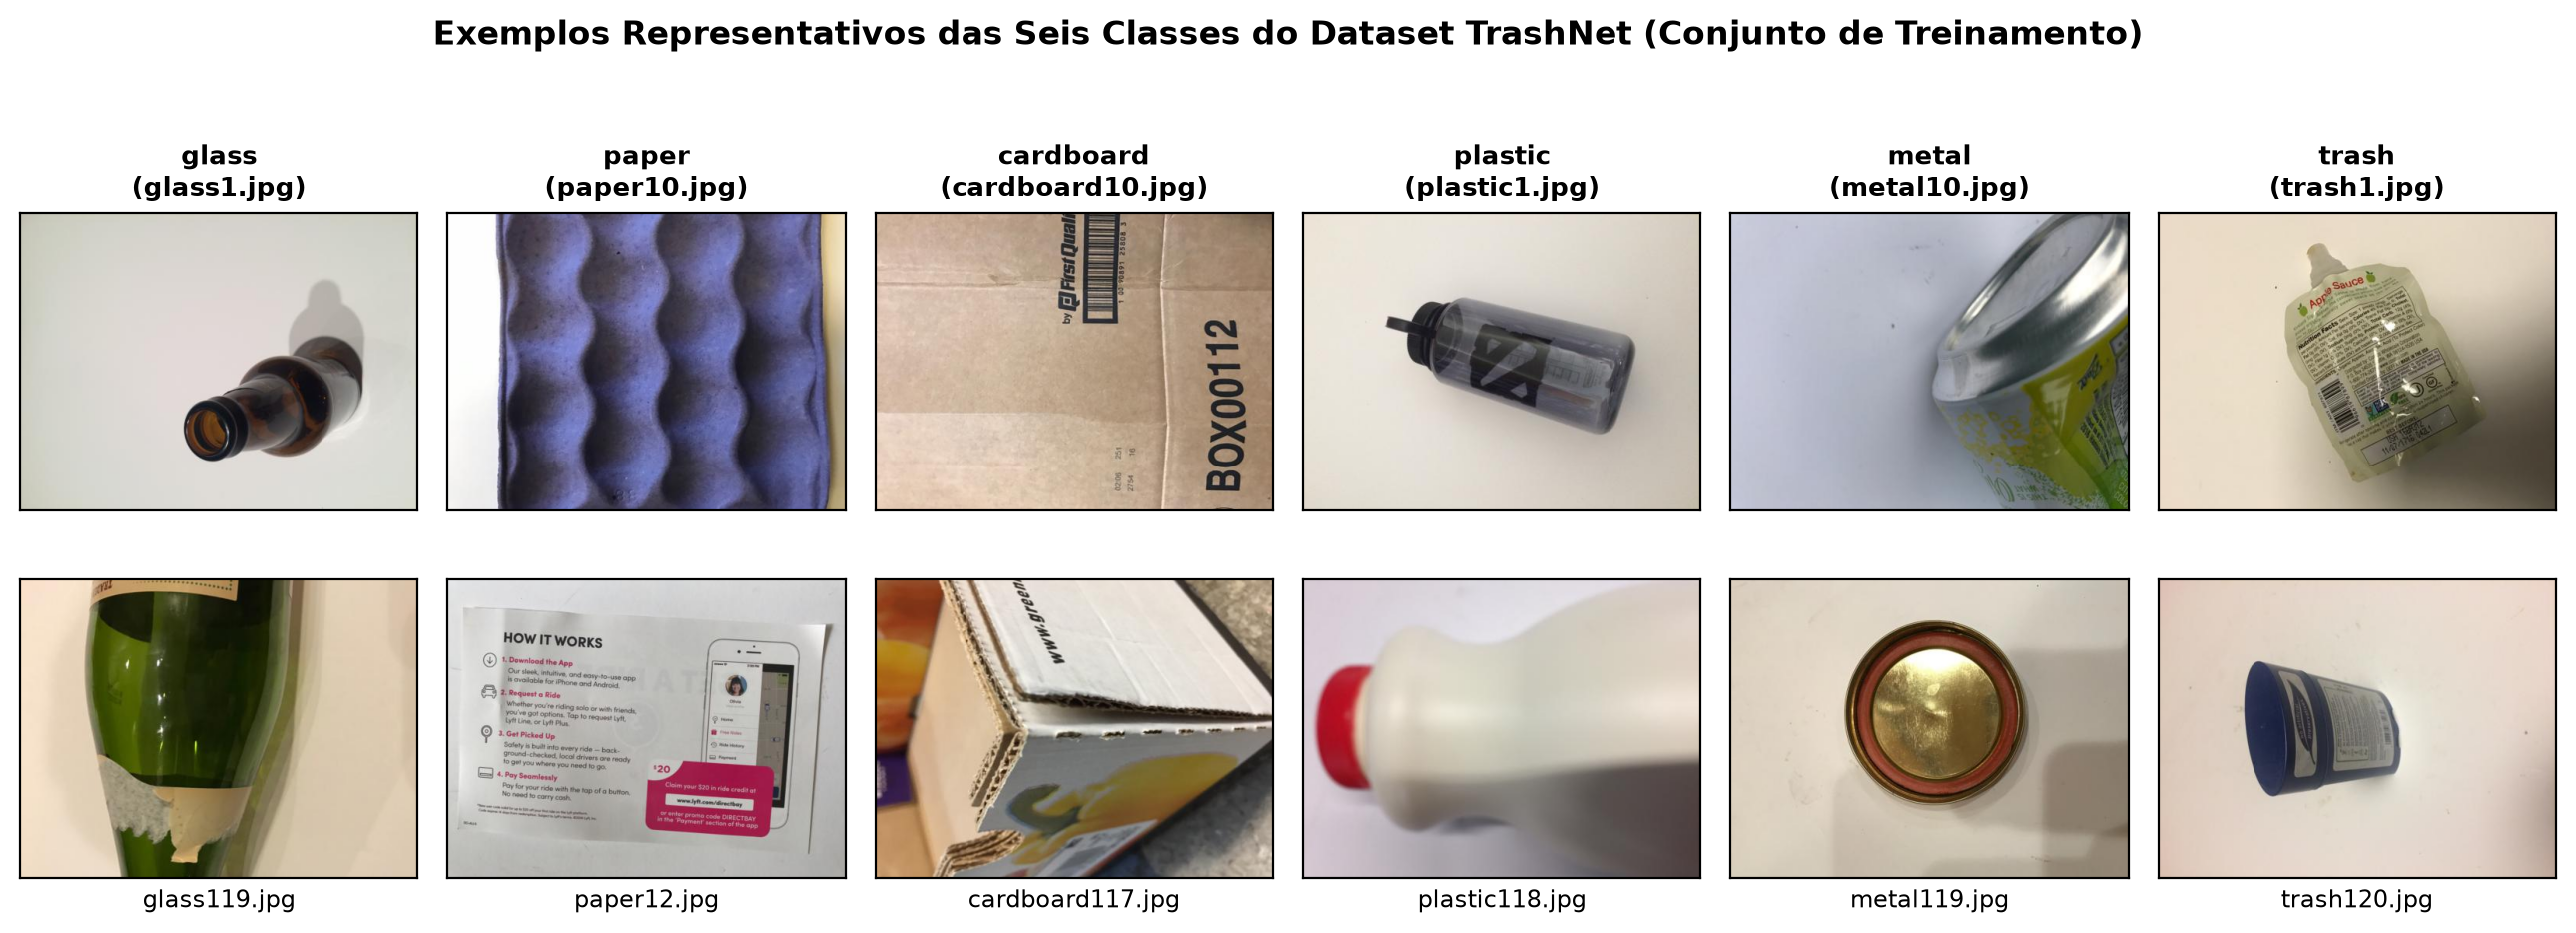

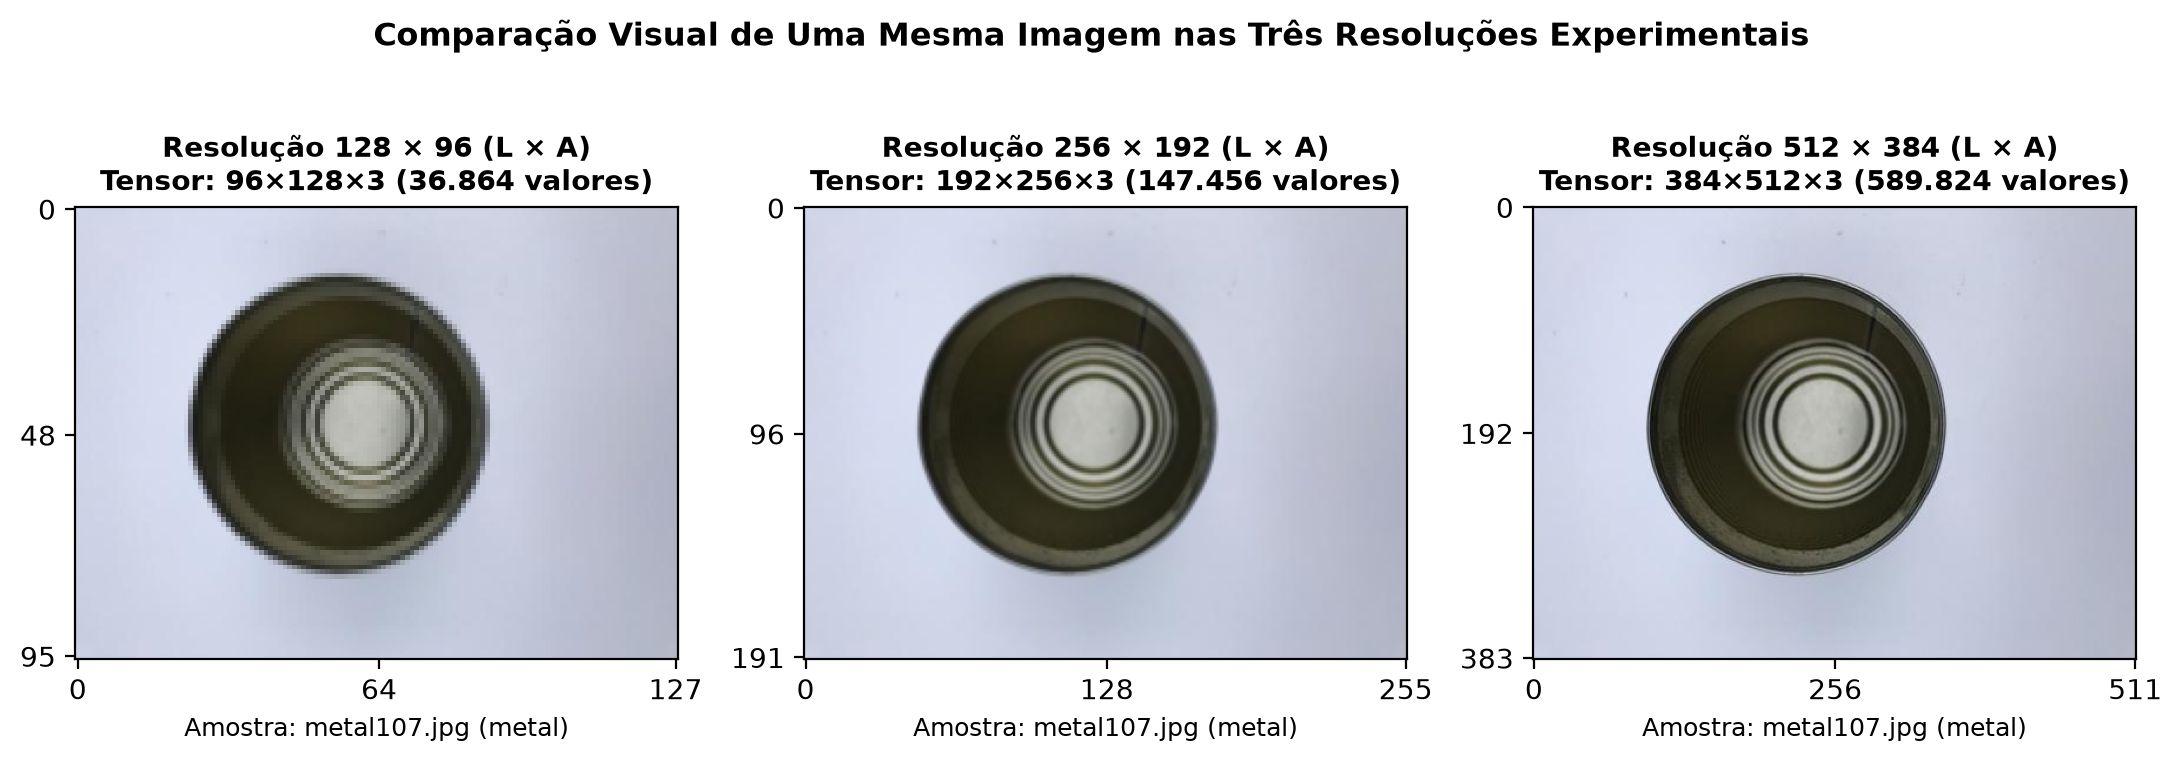

In [3]:
for fig_name in ['fig1_distribuicao_classes.png', 'fig2_exemplos_classes.png', 'fig3_comparacao_resolucoes.png']:
    display(Image(filename=str(BASE_DIR / 'results' / 'figures' / fig_name)))